# Seminar. Steady-state heat conduction in a piston: the axisymmetric finite element method

**Topic:** calculation of the steady-state temperature field in an internal combustion engine piston using an axisymmetric formulation, linear triangular finite elements, and Python.

**Objective:** apply the algorithm introduced for heat conduction in a plate to an engine component and demonstrate how the element matrices and boundary integrals change in an axisymmetric formulation.

In this seminar, we will:

1. Define the physical model and its mathematical formulation.
2. Load the prepared piston mesh with named physical boundary groups.
3. Derive the element conductivity matrix in $(r,z)$ coordinates.
4. Assemble the global matrix and use the predefined boundary regions.
5. Prescribe convective heat exchange with the gas, oil, and adjacent components.
6. Solve the system of equations and examine the temperature field.

**Connection to the previous seminar:** approximation using a linear triangular finite element, shape functions, the variational principle, and global matrix assembly remain unchanged. The main difference is the **weight $2\pi r$**, which accounts for rotation of the meridional cross-section about the axis of symmetry.

**Video resources:** [video 1](https://www.youtube.com/watch?v=YxowmVx28yU), [video 2](https://www.youtube.com/watch?v=Kk2t4AOI5xM), [video 3](https://www.youtube.com/watch?v=wIt4JFuWPGs).

## Libraries and file paths

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve
from pathlib import Path
# Dictionary import
import json

In [2]:
# Prepared mesh data for the heat conduction analysis.
mesh_dir = Path("_mesh")

## 1. Physical model

We consider an axisymmetric body representing an internal combustion engine piston. Its three-dimensional geometry is obtained by rotating a meridional cross-section about the $z$-axis.

The assumptions are:

- steady-state heat conduction;
- a homogeneous, isotropic material with constant thermal conductivity $\lambda$;
- no internal heat generation;
- temperature independent of the circumferential coordinate: $\partial T/\partial\varphi=0$;
- heat transfer between individual surface regions and their surroundings described by Newton's law of cooling.

The heat conduction equation in cylindrical coordinates is:

$$
\boxed{
\frac{1}{r}\frac{\partial}{\partial r}
\left(r\lambda\frac{\partial T}{\partial r}\right)
+
\frac{\partial}{\partial z}
\left(\lambda\frac{\partial T}{\partial z}\right)=0.
}
$$

On surfaces subject to convective heat transfer, we prescribe:

$$
-\lambda\frac{\partial T}{\partial n}=\alpha(T-T_\infty),
$$

Here, $n$ denotes the outward normal to the meridional boundary, $\alpha$ is the convective heat transfer coefficient, and $T_\infty$ is the temperature of the corresponding surrounding medium. A positive heat flux $q_{\mathrm{out}}=\alpha(T-T_\infty)$ is directed **out of the piston**. If a heat flux *into the body* is prescribed separately, we use the convention from the previous seminar: $q_{\mathrm{in}}>0$.

On the axis of symmetry, $r=0$, regularity of the temperature field requires $\partial T/\partial r=0$. Other boundary regions without prescribed heat transfer are assumed to be thermally insulated.

## 2. Prepared mesh and boundary regions

In the separate preprocessing notebook, we imported the CAD geometry with physical groups, generated the mesh in Gmsh, and obtained the arrays `pnts` and `elms` and the `boundary` dictionary.

In this seminar, we **do not regenerate the mesh**. We load `nodes.csv`, `elements.csv`, and `boundary.json`. This allows us to focus on the physical model, the derivation of the element matrices, and assembly of the finite element system.

Place these three files in the `_mesh` subdirectory of the notebook's working directory. Keep them together as a consistent set from the same mesh.

The array `pnts` contains the $(r,z)$ coordinates in meters, `elms` contains the triangle vertex indices, `boundary[name]['edges']` contains the pairs of node indices defining boundary edges, and `boundary[name]['length']` contains the edge lengths. All indices refer to rows of `pnts` and are zero-based.

In [3]:
km = 45.0  # Thermal conductivity, W/(m·K)

In [4]:
pnts = np.loadtxt(
    mesh_dir / "nodes.csv",
    delimiter=",", skiprows=1, ndmin=2)

elms = np.loadtxt(
    mesh_dir / "elements.csv",
    delimiter=",", skiprows=1, dtype=int, ndmin=2)

with open(mesh_dir / "boundary.json", encoding="utf-8") as f:
    boundary = json.load(f)

In [5]:
# Store the node and element counts for subsequent loops.
nn = len(pnts)
ne = len(elms) 

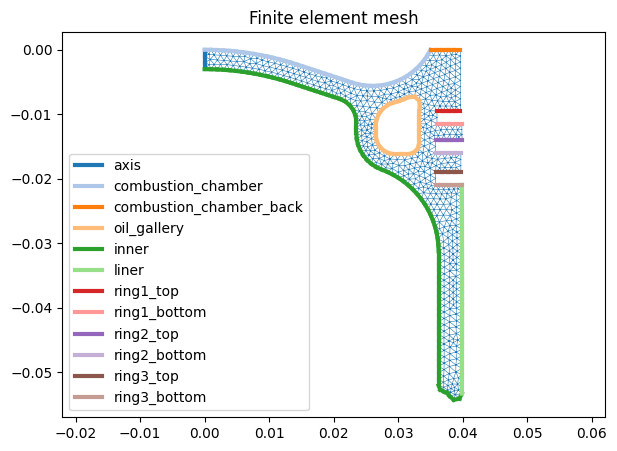

In [6]:
# Display all physical groups.
colors = plt.get_cmap("tab20").colors
# Create the plot.
fig, ax = plt.subplots(figsize=(7,5))
plt.title('Finite element mesh')
ax.triplot(pnts[:,0]  , pnts[:,1]  , elms, linewidth=0.4)
for i, bc in enumerate(boundary):
    edges = boundary[bc]['edges']
    plt.plot(pnts[edges, 0].T, pnts[edges, 1].T, color=colors[i], lw=3)
    plt.plot([], [], color=colors[i], lw=3, label=bc)
plt.axis('equal')
plt.legend(loc='lower left')
plt.show()

## 3. Conductivity matrix of an axisymmetric triangular element

As in the plate problem, temperature within a linear triangular element is approximated using its three nodal values:

$$
T(r,z)=N_i(r,z)T_i+N_j(r,z)T_j+N_m(r,z)T_m.
$$

The shape functions are linear, so the temperature derivatives with respect to $r$ and $z$ are constant within each element:

$$
\begin{pmatrix}
\partial T/\partial r\\[2pt]
\partial T/\partial z
\end{pmatrix}
=\frac{1}{\Delta_e}
\underbrace{\begin{pmatrix}
b_i&b_j&b_m\\
c_i&c_j&c_m
\end{pmatrix}}_{\mathbf H}
\begin{pmatrix}T_i\\T_j\\T_m\end{pmatrix},
$$

Here, $\Delta_e$ is the **signed** coordinate determinant, and the element area is $A_e=|\Delta_e|/2$.

The shape-function coefficients are calculated from the vertex coordinates $(r_i,z_i)$, $(r_j,z_j)$, and $(r_m,z_m)$:

$$
\begin{aligned}
\mathbf b&=(z_j-z_m,\ z_m-z_i,\ z_i-z_j),\\
\mathbf c&=(r_m-r_j,\ r_i-r_m,\ r_j-r_i).
\end{aligned}
$$

### Why does the radius appear in an axisymmetric formulation?

In the planar plate problem, the differential volume is $dV=t\,dA$, where $t$ is the thickness. Rotating the element about the axis of symmetry gives:

$$
\boxed{dV=2\pi r\,dA.}
$$

The conduction contribution to the functional is therefore:

$$
\Phi_{e}^{(\lambda)}
=\frac{\lambda}{2}\int_{V_e}|\nabla T|^2\,dV
=\pi\lambda\int_{A_e}r\left[
\left(\frac{\partial T}{\partial r}\right)^2+
\left(\frac{\partial T}{\partial z}\right)^2\right]dA.
$$

Because $\nabla T$ is constant within a linear element and $r$ is a linear coordinate, the radius integral is evaluated exactly:

$$
\int_{A_e}r\,dA=A_e\bar r_e,\qquad
\bar r_e=\frac{r_i+r_j+r_m}{3}.
$$

Hence:

$$
\Phi_e^{(\lambda)}=\frac12\{T\}_e^{\mathsf T}\mathbf K_e\{T\}_e,
$$

$$
\boxed{\mathbf K_e=\frac{\pi\lambda\bar r_e}{2A_e}\,\mathbf H^{\mathsf T}\mathbf H.}
$$

**Comparison with the plate:** the coefficient multiplying $\mathbf H^{\mathsf T}\mathbf H$ was $\lambda t/(4A_e)$. Here, the constant thickness is replaced by the circumference $2\pi r$.

Physical meaning of $\bar r_e$: elements with the same shape and area represent larger material volumes when located farther from the axis.

### Stationarity of the functional

As in the previous seminar, **the finite element matrix and load vector follow from stationarity of the functional with respect to the unknown nodal temperatures**.

After substituting the shape functions and assembling all volume and boundary contributions, the total functional is a quadratic function of the nodal temperatures:

$$
\Phi(\mathbf T)=\frac12\mathbf T^{\mathsf T}\mathbf K\mathbf T-\mathbf T^{\mathsf T}\mathbf F+C.
$$

Here, $\mathbf K$ contains the element conductivity matrices and the boundary convection matrices; $\mathbf F$ contains the boundary thermal load vectors; and $C$ is independent of the unknown temperatures.

Thus:

$$
\frac{\partial\Phi}{\partial\mathbf T}=\mathbf K\mathbf T-\mathbf F=\mathbf 0,
$$

which gives the system:

$$
\boxed{\mathbf K\mathbf T=\mathbf F.}
$$

The constant $C$ does not affect the system because its derivatives with respect to the nodal temperatures are zero. In this piston problem, no temperatures are prescribed directly: all prescribed heat transfer conditions are of Robin type (third-kind boundary conditions).

In [7]:
# Define a function that computes the element conductivity matrix.
def get_kel(element, km):
    i , j , m = element
    ri, zi = pnts[i]
    rj, zj = pnts[j]
    rm, zm = pnts[m]
    r_avg = (ri + rj + rm) / 3.0
    area = 0.5 * abs((rj-ri)*(zm-zi) - (zj-zi)*(rm-ri))
    b = np.array([zj-zm, zm-zi, zi-zj])
    c = np.array([rm-rj, ri-rm, rj-ri])
    H = np.array([b, c])
    Kel = np.pi * km * r_avg / (2 * area) * (H.T @ H)                     # Matrix multiplication, not elementwise multiplication.
    return Kel   

### Checking the element matrix

If all three nodal temperatures are equal, $T_i=T_j=T_m$, the temperature gradient vanishes. Therefore:

$$
\mathbf K_e\begin{pmatrix}1\\1\\1\end{pmatrix}=\mathbf 0.
$$

The element matrix must be symmetric and positive semidefinite. Its row sums are zero to within floating-point round-off.

In [8]:
Ke0 = get_kel(elms[0], km = km)
print('Conductivity matrix of one element:\n', Ke0)
print('Symmetric:', np.allclose(Ke0, Ke0.T))
print('Row sums (should be close to 0):', Ke0.sum(axis=1))

Conductivity matrix of one element:
 [[ 4.52147813 -2.49909503 -2.0223831 ]
 [-2.49909503  6.60072842 -4.10163339]
 [-2.0223831  -4.10163339  6.12401649]]
Symmetric: True
Row sums (should be close to 0): [ 0.00000000e+00 -1.77635684e-15  8.88178420e-16]


## 4. Global matrix assembly

Each triangle has three global node indices stored in a row of `elms`. The element matrix $\mathbf K_e$ is added to the corresponding entries of the global matrix.

As before:

$$
\mathbf K_{\mathrm{glob}}\mathbf T=\mathbf F_{\mathrm{glob}}.
$$

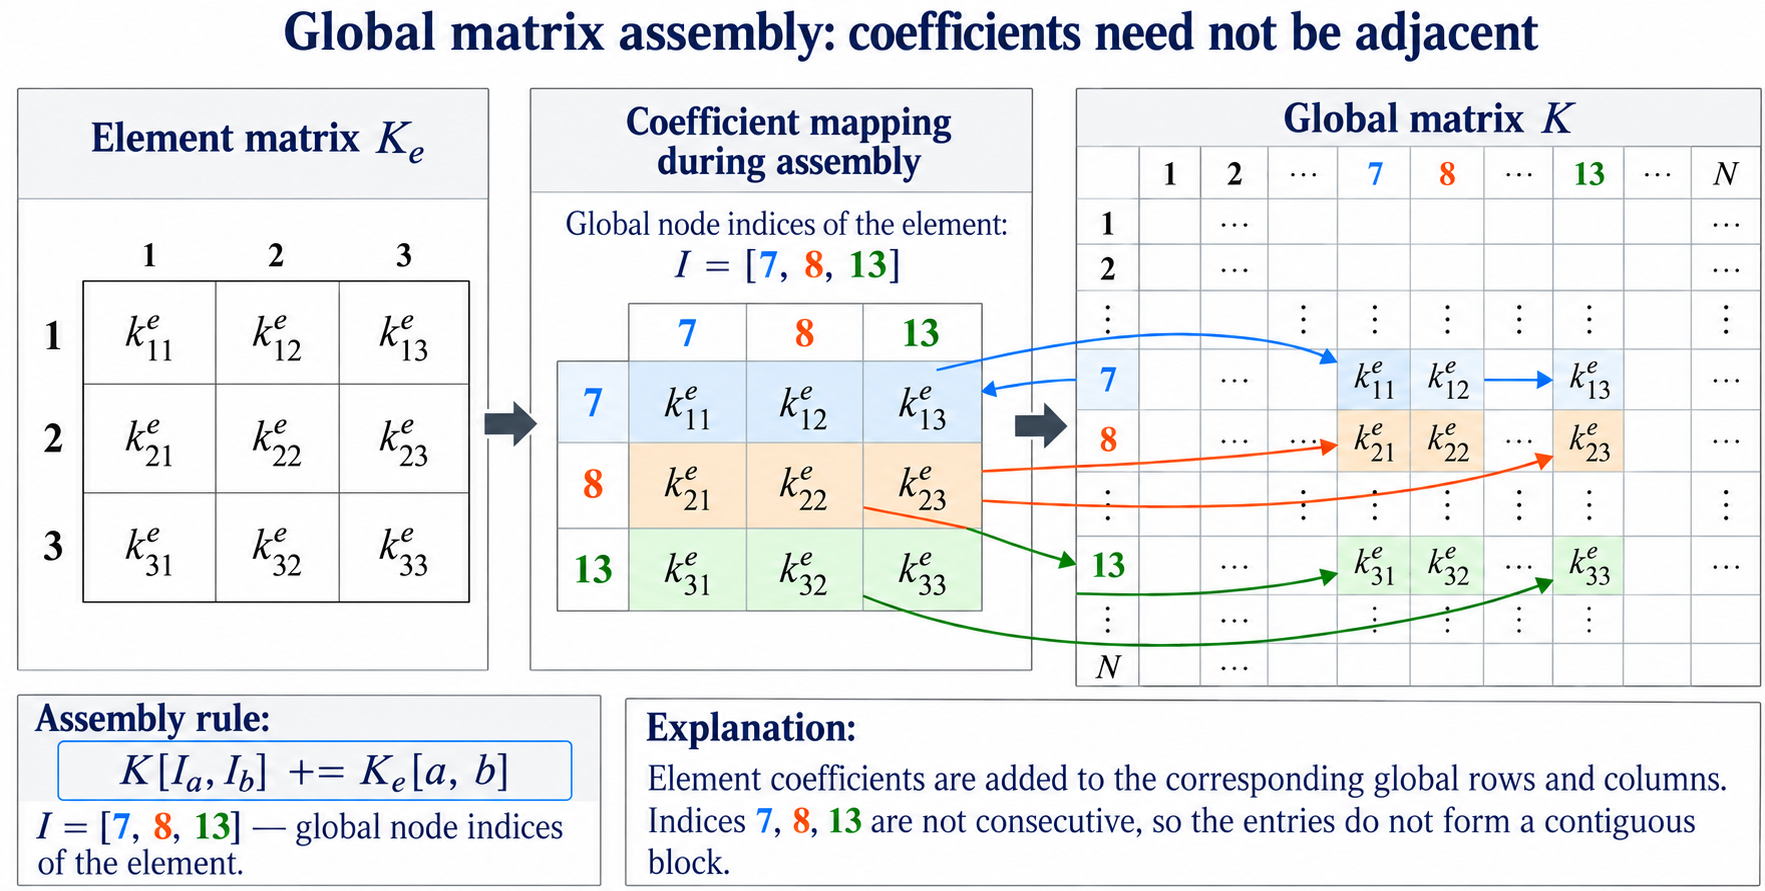

In [9]:
Kglob  = np.zeros([nn, nn])
Fglob = np.zeros(nn)

In [10]:
# Use np.ix_ to select the submatrix associated with the element nodes.
for el in range(ne):
    IndX =elms[el]
    IndXArr = np.ix_(IndX, IndX)
    Kglob[IndXArr] += get_kel(elms[el], km = km)    

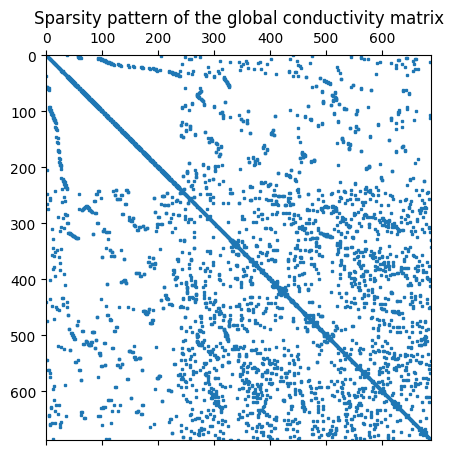

In [11]:
plt.figure(figsize=(5, 5))
plt.spy(Kglob, markersize=2)
plt.title('Sparsity pattern of the global conductivity matrix')
plt.show()

## 5. Piston boundary regions

In the previous plate seminar, the boundaries were identified from their coordinates. In this calculation, they have already been labeled as physical groups in Gmsh and stored in the `boundary` dictionary.

To assemble the convection terms, we use the node pairs defining each boundary edge and the edge lengths. The plot above shows the locations of the boundary regions. Unassigned regions are treated as thermally insulated.

### Boundary contribution to the functional

In an axisymmetric problem, rotating a boundary edge $\Gamma_e$ generates a surface with differential area:

$$dS=2\pi r\,dL.$$

The convection contribution to the functional is therefore:

$$
\Phi_{\Gamma,e}^{(\alpha)}
=\frac12\int_{S_{\Gamma,e}}\alpha(T-T_\infty)^2\,dS
=\pi\alpha\int_{\Gamma_e}r(T-T_\infty)^2\,dL.
$$

Temperature and radius vary linearly along the edge through the shape functions:

$$T=N_iT_i+N_jT_j,\qquad r=N_i r_i+N_jr_j.$$

Substituting these expressions into the functional and differentiating with respect to $T_i,T_j$, as in the previous seminar, gives:

$$
\frac{\partial\Phi_{\Gamma,e}^{(\alpha)}}{\partial\{T\}_\Gamma}
=\mathbf K_{\Gamma,e}\{T\}_\Gamma-\mathbf F_{\Gamma,e}.
$$

For a linear edge, the exact integrals are:

$$
\begin{aligned}
\int_{\Gamma_e}rN_i^2\,dL&=\frac{L}{12}(3r_i+r_j),\\
\int_{\Gamma_e}rN_iN_j\,dL&=\frac{L}{12}(r_i+r_j),\\
\int_{\Gamma_e}rN_j^2\,dL&=\frac{L}{12}(r_i+3r_j),\\
\int_{\Gamma_e}rN_i\,dL&=\frac{L}{6}(2r_i+r_j),\\
\int_{\Gamma_e}rN_j\,dL&=\frac{L}{6}(r_i+2r_j).
\end{aligned}
$$

The **element convection matrix** is:

$$
\boxed{
\mathbf K_{\Gamma,e}=
\frac{\pi\alpha L}{6}
\begin{pmatrix}
3r_i+r_j&r_i+r_j\\
r_i+r_j&r_i+3r_j
\end{pmatrix}
}
$$

and the **element thermal load vector** is:

$$
\boxed{
\mathbf F_{\Gamma,e}=
\frac{\pi\alpha T_\infty L}{3}
\begin{pmatrix}
2r_i+r_j\\
r_i+2r_j
\end{pmatrix}.
}
$$

Unlike in the planar problem, the load is not necessarily shared equally between the two nodes: if $r_i\ne r_j$, the circumferences of rotation at the nodes differ. These expressions account **exactly** for the linear variation of radius along the edge, without the approximation $r\approx\bar r$.

In [12]:
def bc3type(K, F, boundary, hinf, Tinf):
    edges = boundary['edges']
    L = boundary['length']
    for nds, length in zip(edges, L):
        ri, _ = pnts[nds[0]]
        rj, _ = pnts[nds[1]]
      
        F[nds] += np.pi * length * hinf *Tinf / 3 * np.array( [2*ri+rj,
                                                         ri+2*rj])
        IndXArr = np.ix_(nds, nds)
        K[IndXArr] += np.pi* hinf *  length / 6 * np.array([[3*ri+rj, ri+rj],
                                                     [ri+rj,   ri+3*rj]])
    return K, F 

| Boundary region | $T_\infty$, °C | $\alpha$, W/(m²·K) |
|---|---:|---:|
| Combustion chamber (`combustion_chamber`) | 700 | 650 |
| Combustion chamber (`combustion_chamber_back`) | 700 | 350 |
| Oil gallery (`oil_gallery`) | 85 | 1750 |
| Internal surfaces (`inner`) | 85 | 250 |
| Outer skirt surface (`liner`) | 135 | 3000 |
| First ring groove — upper flank (`ring1_top`) | 185 | 600 |
| First ring groove — lower flank (`ring1_bottom`) | 175 | 6000 |
| Second ring groove — upper flank (`ring2_top`) | 165 | 180 |
| Second ring groove — lower flank (`ring2_bottom`) | 160 | 4000 |
| Third ring groove — upper flank (`ring3_top`) | 150 | 750 |
| Third ring groove — lower flank (`ring3_bottom`) | 145 | 750 |

In [13]:
Kcalc = Kglob.copy()
Fcalc = Fglob.copy()
# Convection parameters:
# Physical group name -> (heat transfer coefficient alpha, ambient temperature Tinf).
bc_params = {
    "combustion_chamber":      (650, 700),
    "combustion_chamber_back": (350, 700),
    "oil_gallery":             (1750, 85),
    "inner":                   (250, 85),
    "liner":                   (3000, 135),
    "ring1_top":               (600, 185),
    "ring1_bottom":            (6000, 175),
    "ring2_top":               (180, 165),
    "ring2_bottom":            (4000, 160),
    "ring3_top":               (750, 150),
    "ring3_bottom":            (750, 145),
}
for name, (alpha, Tinf) in bc_params.items():
    # boundary[name]['edges'] contains node indices into pnts.
    Kcalc, Fcalc = bc3type(Kcalc, Fcalc, boundary[name], alpha, Tinf)

In [14]:
T_sol = np.linalg.solve(Kcalc, Fcalc)

**Temperature field visualization**

The solution array `T_sol` contains the temperature at each mesh node. Within each element, temperature is interpolated using the linear shape functions. We plot the temperature field in the meridional cross-section.

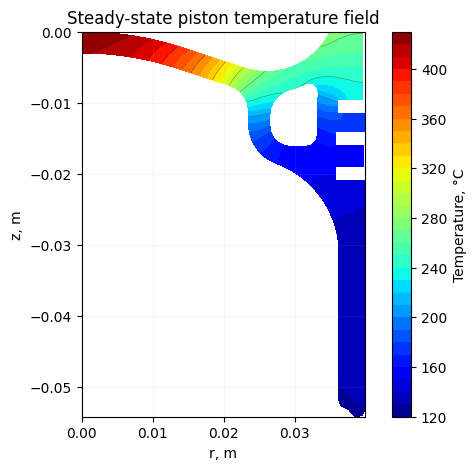

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
field = ax.tricontourf(pnts[:, 0], pnts[:, 1], elms, T_sol,
                       levels=30, cmap='jet')
ax.tricontour(pnts[:, 0], pnts[:, 1], elms, T_sol,
              levels=10, colors='black', linewidths=0.3, alpha=0.55)
plt.colorbar(field, ax=ax, label='Temperature, °C')
ax.set(xlabel='r, m', ylabel='z, m', title='Steady-state piston temperature field')
ax.set_aspect('equal')
ax.grid(alpha=0.1)
plt.show()

## 6. Seminar conclusions

In this seminar, we developed a Python program to calculate the steady-state temperature field of an **internal combustion engine piston using an axisymmetric formulation**.

The main finite element analysis steps were completed in sequence: loading the prepared meridional mesh with named physical groups, deriving the element matrix from the variational functional, assembling the global matrix, identifying the heat transfer regions, and solving the system of linear algebraic equations.

Compared with the previous seminar on heat conduction in a plate, the **overall finite element algorithm remains unchanged**. The main mathematical difference is the factor $2\pi r$ in the volume and surface integrals, which accounts for axial symmetry. This factor determines the form of the matrices for the axisymmetric triangular element and its boundary edges.